# cycleVI on the RNA of the CRISPR screen

[CycleVI](https://doi.org/10.1101/2025.11.04.686009) learns a circular position in the cell cycle for each cell, plus an embedding with the cell cycle removed. We ran it on the raw RNA counts of all QC-passing cells. This notebook first checks the inferred position against same-cell imaging, which the model never saw. It then uses the knockouts as readouts along the cycle. They can't serve as anchors because the library has no cell cycle regulators.

In [1]:
import pickle
from pathlib import Path

import anndata as ad
import mantispy as mt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, cross_val_predict, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA, RESULTS = Path("data"), Path("cyclevi")
RUN = "nobatch400"
CACHE = Path("cache") / RUN
CACHE.mkdir(parents=True, exist_ok=True)


def cached(name, compute):
    # returns a saved result, or computes and saves it; delete the cache folder after changing inputs
    path = CACHE / f"{name}.pkl"
    if path.exists():
        return pickle.loads(path.read_bytes())
    result = compute()
    path.write_bytes(pickle.dumps(result))
    return result



img = ad.read_h5ad(DATA / "imaging.h5ad")
img = img[~img.obs["qc_fail"].values].copy()
rna = ad.read_h5ad(DATA / "rna.h5ad")
rna = rna[~rna.obs["qc_fail"].values].copy()
rna.layers.clear()
angle_raw = pd.read_csv(RESULTS / f"{RUN}_angles.csv", index_col=0)["cycle_angle"]
z_cycle = pd.read_csv(RESULTS / f"{RUN}_cycle.csv", index_col=0)
z_other = pd.read_csv(RESULTS / f"{RUN}_other.csv", index_col=0)
assert (angle_raw.index == rna.obs_names).all() and (rna.obs_names == img.obs_names).all()
detected = np.asarray((rna.X > 0).mean(0)).ravel()
rna.obs["log_counts"] = np.log1p(rna.obs["rna_total_counts"])
sc.pp.normalize_total(rna, target_sum=1e4)
sc.pp.log1p(rna)
wells = rna.obs["Well"].astype(str).values
rna.shape

(206091, 54949)

## Main biological findings

- **The clock follows the known order of the cell cycle.** Genes the model wasn't given peak in the expected order, from CCNE1 and E2F1 at G1/S through FOXM1 and CCNA2 to CCNB1 at G2/M. DNA content, which the model never saw, rises along the same path and then falls.
- **The clock shows an abrupt change that looks like cell division.** Between 120 and 150 degrees DNA content, nuclear area, cell area and RNA depth all drop together.
- **Signalling changes along the cycle.** Phospho-p38 and phospho-ERK peak just after DNA content, at the point where cells appear to divide. A p53 target programme (MDM2, CDKN1A) and CCND1 follow in the arc after division.
- **The CTNNB1 knockout moves the RNA clock, but imaging doesn't confirm a change in the cycle.** We treat it as an open question.
- **The angle isn't final.** Training hadn't converged at 400 epochs, and a run corrected for well gave a different angle (circular correlation 0.19). The order of events is well supported, but exact angles aren't.

## Is the position a circle, and is it stable?

A usable position needs cells arranged around a ring with no gap at the centre being filled, and it should agree between runs. We compare runs with the circular correlation, which ignores where the angle starts.

Radius quantiles (5, 25, 50, 75, 95%): [0.708, 1.039, 1.277, 1.518, 1.926]


Circular correlation with other runs: {'nobatch': 0.736, 'well': 0.189}


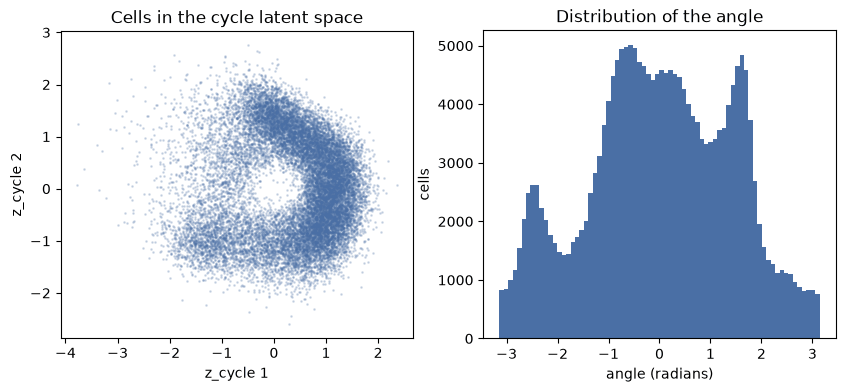

In [2]:
def circular_corr(a, b):
    sa, sb = np.sin(a - stats.circmean(a, high=np.pi, low=-np.pi)), np.sin(b - stats.circmean(b, high=np.pi, low=-np.pi))
    return (sa * sb).sum() / np.sqrt((sa**2).sum() * (sb**2).sum())


radius = np.hypot(z_cycle.iloc[:, 0], z_cycle.iloc[:, 1])
print("Radius quantiles (5, 25, 50, 75, 95%):", radius.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(3).tolist())
stability = {}
for other_run in ["nobatch", "well", "nobatch400"]:
    path = RESULTS / f"{other_run}_angles.csv"
    if path.exists() and other_run != RUN:
        stability[other_run] = round(float(circular_corr(angle_raw.values, pd.read_csv(path, index_col=0)["cycle_angle"].values)), 3)
print("Circular correlation with other runs:", stability)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sample = np.random.default_rng(0).choice(len(z_cycle), 20000, replace=False)
axes[0].scatter(z_cycle.iloc[sample, 0], z_cycle.iloc[sample, 1], s=1, alpha=0.2, color="#4a6fa5")
axes[0].set(xlabel="z_cycle 1", ylabel="z_cycle 2", title="Cells in the cycle latent space", aspect="equal")
axes[1].hist(angle_raw, bins=72, color="#4a6fa5")
axes[1].set(xlabel="angle (radians)", ylabel="cells", title="Distribution of the angle")
plt.show()

## Fixing the start and direction with marker genes

The angle has no fixed start or direction. We set position 0 at the peak of the S score and choose the direction that reaches the G2/M peak by the shorter arc. The model was initialised from these same markers, so this step says nothing about whether the position is correct. The checks after it use data that the model didn't see.

In [3]:
S_GENES = """MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 CENPU HELLS RFC2 RPA2 NASP
RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 BLM CASP8AP2 USP1
CLSPN POLA1 CHAF1B BRIP1 E2F8""".split()
G2M_GENES = """HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 PIMREG SMC4 CCNB2
CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 JPT1 CDC20 TTK CDC25C KIF2C RANGAP1 NCAPD2
DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF NEK2 G2E3 GAS2L3 CBX5 CENPA""".split()
sc.tl.score_genes_cell_cycle(rna, s_genes=[g for g in S_GENES if g in rna.var_names], g2m_genes=[g for g in G2M_GENES if g in rna.var_names], random_state=0)
obs = rna.obs


def harmonic_peak(values, theta):
    v = np.asarray(values, dtype=float) - np.mean(values)
    z = (v * np.exp(1j * theta)).mean()
    return float(np.angle(z)), float(2 * np.abs(z))


theta = angle_raw.values
peak_s, _ = harmonic_peak(obs["S_score"], theta)
peak_g2m, _ = harmonic_peak(obs["G2M_score"], theta)
gap = (peak_g2m - peak_s + np.pi) % (2 * np.pi) - np.pi
direction = np.sign(gap)
position = (direction * (theta - peak_s)) % (2 * np.pi)
obs["cycle_position"] = position
print(f"G2M peak is {abs(gap):.2f} radians ({abs(gap) / (2 * np.pi):.1%} of the cycle) after the S peak")

raw = pd.DataFrame(img.layers["raw"], index=img.obs_names, columns=img.var_names)
dna_raw = ((raw["Nucleus_Nuclear"] - raw["Bkg_Nucleus_Nuclear"]) * raw["NuclearArea"]).clip(lower=1)
obs["dna"] = (np.log2(dna_raw) - np.log2(dna_raw).groupby(wells).transform("median")).values
obs["nuclear_area"], obs["cell_area"] = raw["NuclearArea"].values, raw["Area"].values
bins = pd.cut(position, np.linspace(0, 2 * np.pi, 13), include_lowest=True, labels=[f"{i * 30}-{(i + 1) * 30}" for i in range(12)])
table = obs.groupby(bins, observed=True).agg(cells=("dna", "size"), S=("S_score", "median"), G2M=("G2M_score", "median"), dna=("dna", "median"), nuclear_area=("nuclear_area", "median"), cell_area=("cell_area", "median"), log_counts=("log_counts", "median"))
table.index.name = "position (degrees, 0 = S peak)"
table.round(3)

G2M peak is 1.64 radians (26.1% of the cycle) after the S peak


,cells,S,G2M,dna,nuclear_area,cell_area,log_counts
"position (degrees, 0 = S peak)",,,,,,,
0-30,27202,0.143,0.122,-0.017,848.0,3759.0,7.329
30-60,23412,0.112,0.185,0.182,886.0,3937.5,7.382
60-90,21392,0.070,0.259,0.358,921.0,4024.0,7.405
90-120,24525,0.025,0.325,0.496,934.0,4083.0,7.417
120-150,8260,-0.027,0.199,-0.067,693.0,2927.0,7.071
150-180,5620,-0.045,0.098,-0.203,705.0,2911.0,7.054
180-210,5519,-0.064,0.020,-0.200,765.0,3158.0,7.112
210-240,13674,-0.073,-0.037,-0.116,873.0,4066.0,7.327
240-270,9686,-0.012,-0.027,-0.217,804.0,3603.0,7.223


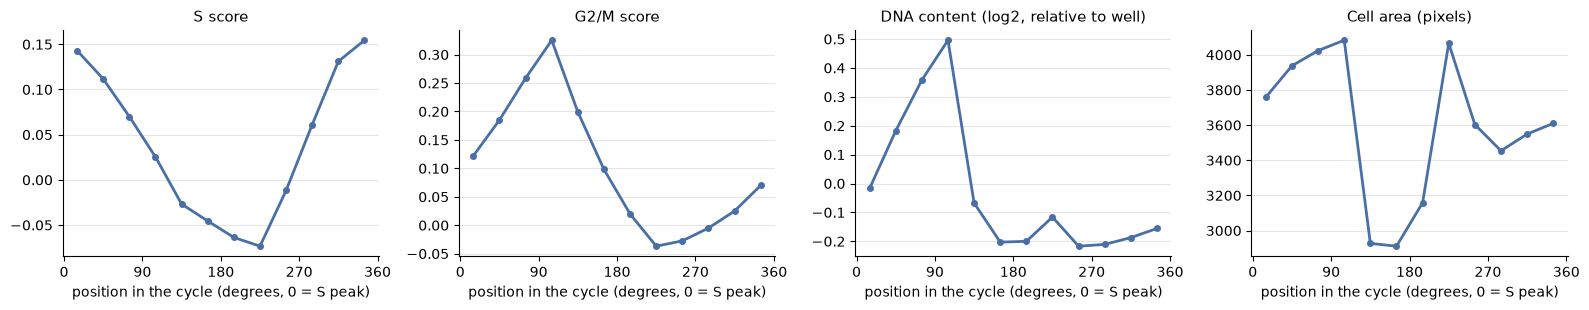

In [4]:
centres = np.radians(np.arange(15, 360, 30))
panels = {"S score": table["S"], "G2/M score": table["G2M"], "DNA content (log2, relative to well)": table["dna"], "Cell area (pixels)": table["cell_area"]}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2), sharex=True)
for ax, (title, values) in zip(axes, panels.items()):
    ax.plot(np.degrees(centres), values.values, color="#4a6fa5", lw=2, marker="o", ms=4)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("position in the cycle (degrees, 0 = S peak)")
    ax.set_xticks(range(0, 361, 90))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="0.9", lw=0.8)
fig.tight_layout()
plt.show()

### What the table shows about the phases

Reading the table from S onwards, DNA content rises from about -0.02 to +0.50 log2 between 0 and 120 degrees, which is what replication should look like. Between 120 and 150 degrees, DNA content falls by 0.56 log2, cell area falls from 4083 to 2927 and RNA depth falls by about 30%. Cells that divide lose DNA, volume and RNA at the same time, so we read this step as the transition from G2/M to early G1. We expect a full 1 log2 drop in DNA between G2 and G1, and we see about 0.7 in total. The smaller drop is expected if each cell's position has an error of about 30 degrees, because that error mixes neighbouring phases.

The arc from about 120 to 300 degrees then corresponds to G1, and it ends as the S score rises again. Few cells sit between 120 and 210 degrees. One reading is that cells pass through this stretch quickly, but cell counts per sector don't translate directly into time because the angle has no fixed speed. Cell area also has an unexplained bump at 210 to 240 degrees (4066), which we can't interpret yet.

## Is the position right? Tests on data the model didn't see

We use three tests. First, cell cycle genes outside the marker lists should peak in the known order, with G1/S genes before G2/M genes. Second, DNA content and nuclear area should rise and fall along the position. Third, we compare how much of the imaging signal the position explains with how much the two marker scores explain, within wells, and with shuffled positions as a null.

In [5]:
HELD_OUT = {"G1/S": ["CCNE1", "E2F1", "CDT1", "MCM3", "MCM7", "MCM10", "CDC25A", "CHEK1"], "G2/M": ["CCNA2", "CCNB1", "PLK1", "CDC25B", "KIF20A", "PTTG1", "KPNA2"]}
rows = []
for stage, genes in HELD_OUT.items():
    for gene in genes:
        if gene not in rna.var_names or gene in S_GENES + G2M_GENES:
            continue
        values = np.asarray(rna[:, gene].X.todense()).ravel()
        peak, amplitude = harmonic_peak(values, position)
        rows.append({"stage": stage, "gene": gene, "share of cells detecting": (values > 0).mean(), "peak (degrees)": np.degrees(peak) % 360, "amplitude (log expression)": amplitude})
pd.DataFrame(rows).round(3)

,stage,gene,share of cells detecting,peak (degrees),amplitude (log expression)
0,G1/S,CCNE1,0.055,306.051,0.067
1,G1/S,E2F1,0.098,332.731,0.144
2,G1/S,CDT1,0.104,348.191,0.108
3,G1/S,MCM3,0.204,343.558,0.189
4,G1/S,MCM7,0.421,20.073,0.307
5,G1/S,MCM10,0.060,344.826,0.077
6,G1/S,CDC25A,0.024,343.351,0.024
7,G1/S,CHEK1,0.050,14.278,0.030
8,G2/M,CCNA2,0.072,91.070,0.120
9,G2/M,CCNB1,0.232,108.531,0.479


In [6]:
def design(position):
    return np.column_stack([np.ones(len(position)), np.sin(position), np.cos(position), np.sin(2 * position), np.cos(2 * position)])


def r2(y, x):
    y = pd.Series(np.asarray(y, dtype=float))
    y = (y - y.groupby(wells).transform("mean")).to_numpy()
    fit = x @ np.linalg.lstsq(x, y, rcond=None)[0]
    return 1 - ((y - fit) ** 2).sum() / ((y - y.mean()) ** 2).sum()


scores = np.column_stack([np.ones(len(obs)), obs["S_score"], obs["G2M_score"]])
shuffled = np.random.default_rng(0).permutation(position)
targets = {"DNA content": obs["dna"], "nuclear area": obs["nuclear_area"], "cell area": obs["cell_area"], "log counts": obs["log_counts"]}
for channel in ["Phospho-p38", "Phospho-HSP27", "Phospho-ERK1_Phospho-ERK2", "ERK1_ERK2", "Actin", "Mitochondria", "Cell-Membrane"]:
    targets[f"{channel} intensity"] = raw[channel].values
pd.DataFrame({name: {"position": r2(y, design(position)), "S and G2M scores": r2(y, scores), "shuffled position": r2(y, design(shuffled))} for name, y in targets.items()}).T.round(4)

,position,S and G2M scores,shuffled position
DNA content,0.1076,0.1069,0.0
nuclear area,0.0328,0.0294,0.0
cell area,0.0214,0.0541,0.0
log counts,0.0351,0.0826,0.0
Phospho-p38 intensity,0.0992,0.0286,0.0
Phospho-HSP27 intensity,0.0107,0.0036,0.0
Phospho-ERK1_Phospho-ERK2 intensity,0.0699,0.0198,0.0
ERK1_ERK2 intensity,0.0232,0.0178,0.0
Actin intensity,0.0122,0.0124,0.0
Mitochondria intensity,0.0153,0.0150,0.0


### What the tests show

The order of the held-out genes matches textbook biology. CCNE1 comes first (306 degrees), then E2F1, CDT1 and the MCM genes (333 to 20 degrees), then CCNA2 (91 degrees), and finally CCNB1 and PLK1 (105 to 109 degrees). CCNA2 before CCNB1 is the known order of the mitotic cyclins, so the clock resolves order within G2/M as well as the broad phases.

Compared with the marker scores, the position explains about the same amount of DNA content (0.108 and 0.107). The clear gain is in phospho-p38 (0.099 and 0.029) and phospho-ERK (0.070 and 0.020). Both proteins peak at about 125 degrees, just after DNA content peaks (109 degrees) and at the point where cells appear to divide, so a circular position finds a signal that two separate scores mostly miss. p38 and ERK activity around mitosis has been reported before, which fits, but we can't conclude that the kinases are more active. Rounded mitotic cells look brighter in widefield images, and phospho antibodies can cross-react with mitotic phospho-proteins. The check further down looks at part of this.

Imaging can also predict the position directly. We predict the sine and cosine of the position from all selected imaging features on wells the model hasn't seen, and compare the result with the position from RNA.

In [7]:
x = np.nan_to_num(np.clip(np.asarray(img.X), -10, 10))
channel, modality, selected = img.var["channel"].astype(str).values, img.var["modality"].astype(str).values, img.var["selected"].values
predicted = cross_val_predict(make_pipeline(StandardScaler(), Ridge(10)), x[:, selected], np.column_stack([np.sin(position), np.cos(position)]), cv=GroupKFold(6), groups=wells)
image_position = np.arctan2(predicted[:, 0], predicted[:, 1]) % (2 * np.pi)
error = np.abs((image_position - position + np.pi) % (2 * np.pi) - np.pi)
{"circular correlation with RNA position": round(float(circular_corr(image_position, position)), 3), "median error (degrees, 90 = chance)": round(float(np.degrees(np.median(error))), 1)}

{'circular correlation with RNA position': 0.627,
 'median error (degrees, 90 = chance)': 33.8}

Imaging places a cell within about 34 degrees of its RNA position on unseen wells, which is about a tenth of the cycle. The cell cycle state is therefore visible in the images and protein stains of individual cells, and the agreement between two independent measurements is the best evidence that the position describes real biology.

## Does the cycle-free embedding remove the cycle and keep the biology?

We compare cycleVI's `z_other` with a PCA of the same RNA counts on 100,000 cells. `mt.metrics.batch_variance_explained` shows what each embedding contains. kNN, `mt.tl.map` and `mt.tl.edistance` show whether knockouts still separate from non-targeting cells.

In [8]:
index = np.sort(np.random.default_rng(0).choice(rna.n_obs, 100_000, replace=False))
common = detected >= 0.01
hvg = sc.pp.highly_variable_genes(rna[:, common], n_top_genes=2000, inplace=False)["highly_variable"].values
hvg_names = rna.var_names[common][hvg]
pcs = cached("rna_pca", lambda: PCA(30, random_state=0).fit_transform(np.clip(StandardScaler().fit_transform(rna[index, hvg_names].X.toarray()), -10, 10)))
shared = obs.iloc[index].copy()
shared["Metadata_Plate"] = "Cytos-MPS_TNFa"
shared["Metadata_Well"] = shared["Well"].astype(str)
shared["Metadata_Guide"] = shared["guide"].astype(str)
shared["Metadata_Perturbation"] = shared["target_gene"].astype(str)
shared["Metadata_Condition"] = shared["condition"].astype(str)
shared["Metadata_ImageID"] = shared["Well"].astype(str) + "_" + shared["tile_id"].astype(str)
shared["Metadata_ObjectType"] = "cell"
shared["Metadata_ObjectNumber"] = shared["Cell"].astype(int)
shared["position_sin"], shared["position_cos"] = np.sin(shared["cycle_position"]), np.cos(shared["cycle_position"])
views = {"RNA PCA": pcs, "cycleVI z_other": z_other.to_numpy()[index], "cycleVI z_cycle": z_cycle.to_numpy()[index]}


def view(values):
    a = ad.AnnData(X=np.asarray(values, dtype=np.float32), obs=shared.copy())
    a.obsm["X_pca"] = np.asarray(values, dtype=np.float32)
    return a


KEYS = ["position_sin", "position_cos", "S_score", "G2M_score", "dna", "Well", "condition", "target_gene", "log_counts"]
pd.DataFrame({name: mt.metrics.batch_variance_explained(view(v), KEYS).set_index("key")["value"] for name, v in views.items()}).T.round(4)

key,position_sin,position_cos,S_score,G2M_score,dna,Well,condition,target_gene,log_counts
RNA PCA,0.0409,0.0162,0.0111,0.0376,0.0250,0.0305,0.0269,0.0118,0.1071
cycleVI z_other,0.0042,0.0039,0.0023,0.0026,0.0159,0.0196,0.0118,0.0238,0.0315
cycleVI z_cycle,0.4990,0.4218,0.1852,0.3185,0.0477,0.0018,0.0007,0.0040,0.0079


### What the cycle-free embedding keeps and loses

`z_other` removes most of the cycle: the variance explained by position falls about ten times (0.041 to 0.004) and the target gene signal doubles (0.012 to 0.024). DNA content falls less (0.025 to 0.016), which suggests that part of the DNA signal in RNA space doesn't depend on the position, e.g., cell size or ploidy differences.

The knockout results further down show a cost. TNFa separation by kNN falls from 0.84 to 0.62, while CTNNB1 and TGFBR2 improve in `mt.tl.map`. TNFa signal doesn't move to `z_cycle` (0.0007), so the model appears to discard part of it. Biologically this means that `z_other` suits comparisons of knockouts, but shouldn't be used to study the TNFa response.

## Latent spaces coloured by the position

Each panel shows 30,000 cells. The top row is coloured by the cycle position from RNA, with a colour map that wraps around because 0 and 360 degrees are the same point. The bottom row is coloured by DNA content, which the model never saw. If a space contains the cycle, cells of similar colour sit together.

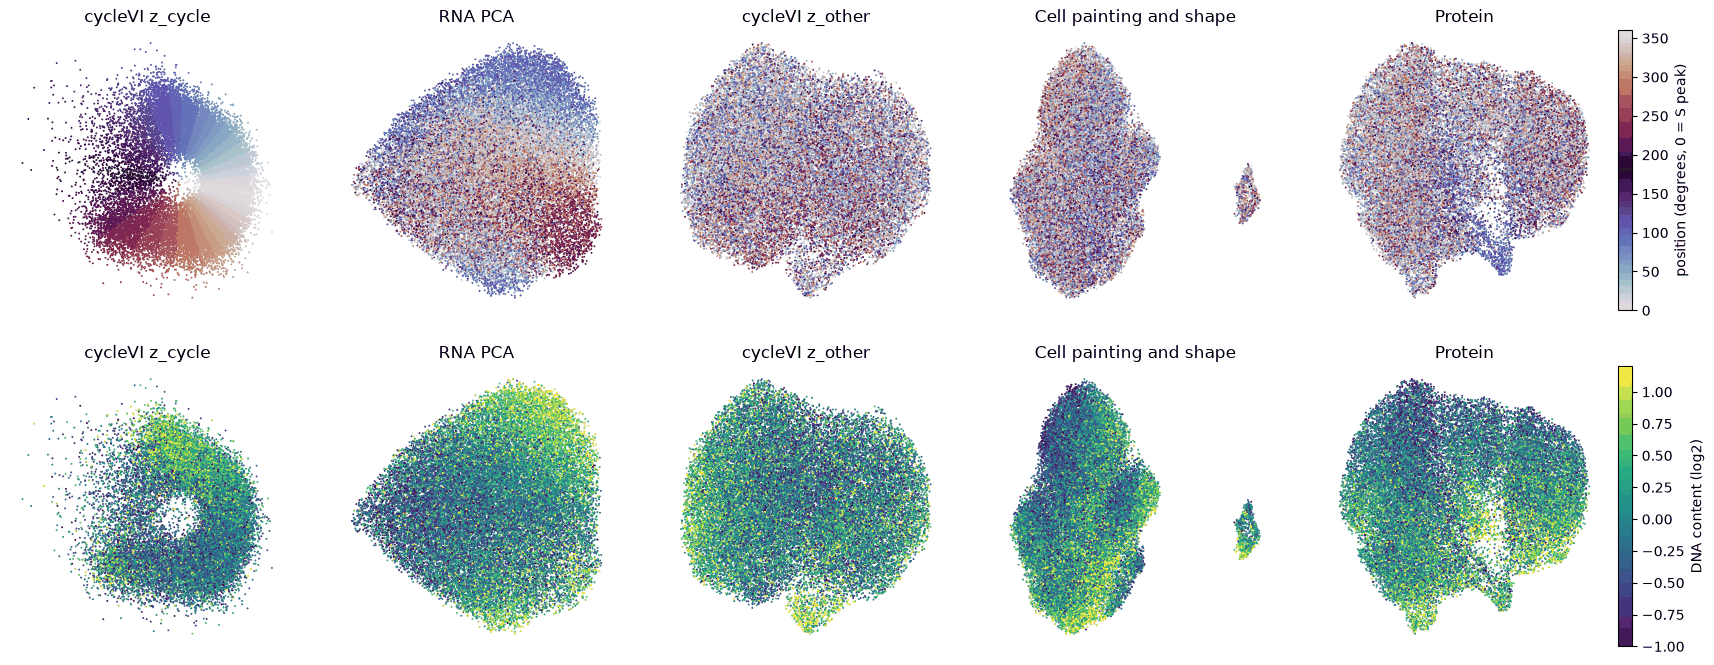

In [9]:
Path("figures").mkdir(exist_ok=True)
sub = np.sort(np.random.default_rng(0).choice(len(index), 30_000, replace=False))
paint_view = PCA(30, random_state=0).fit_transform(x[index][:, selected & np.isin(modality, ["cell_paint", "shape"])])
protein_view = PCA(10, random_state=0).fit_transform(x[index][:, selected & (modality == "protein")])
embeddings = {"RNA PCA": views["RNA PCA"], "cycleVI z_other": views["cycleVI z_other"], "Cell painting and shape": paint_view, "Protein": protein_view}


def umap_layout(values):
    a = ad.AnnData(obs=pd.DataFrame(index=[str(i) for i in sub]), obsm={"X_use": np.asarray(values[sub], dtype=np.float32)})
    sc.pp.neighbors(a, use_rep="X_use", transformer="sklearn")
    sc.tl.umap(a, random_state=0)
    return a.obsm["X_umap"]


layout = {"cycleVI z_cycle": views["cycleVI z_cycle"][sub]}
for name, values in embeddings.items():
    layout[name] = cached(f"umap_{name}", lambda: umap_layout(values))
colours = {"position": (np.degrees(shared["cycle_position"].values[sub]), "twilight", 0, 360), "DNA content": (shared["dna"].values[sub], "viridis", -1, 1.2)}
fig, axes = plt.subplots(2, 5, figsize=(21, 8))
for row, (label, (values, cmap, low, high)) in zip(axes, colours.items()):
    for ax, (name, xy) in zip(row, layout.items()):
        order = np.random.default_rng(1).permutation(len(xy))
        points = ax.scatter(xy[order, 0], xy[order, 1], c=values[order], cmap=cmap, vmin=low, vmax=high, s=2, linewidths=0, rasterized=True)
        ax.set(title=name, xticks=[], yticks=[])
        ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
    fig.colorbar(points, ax=row, fraction=0.012, pad=0.01, label="position (degrees, 0 = S peak)" if label == "position" else "DNA content (log2)")
fig.savefig("figures/latent_spaces.png", dpi=130, bbox_inches="tight")
plt.show()

## Which genes and morphology features follow the position?

For every gene and imaging feature, we fit a sine and cosine of the position within each well on 100,000 cells. `r2` is the variance the position explains. `r2_given_size` is the variance it explains after cell area and RNA depth are accounted for, which matters because many features simply scale with cell size. `peak` is the position where the feature is highest. The full tables are written as CSV.

In [10]:
D = np.column_stack([np.sin(shared["cycle_position"]), np.cos(shared["cycle_position"]), np.sin(2 * shared["cycle_position"]), np.cos(2 * shared["cycle_position"])])
size = np.column_stack([np.log(shared["cell_area"]), shared["log_counts"]])
groups_index = shared["Well"].astype(str).values


def centre(values):
    frame = pd.DataFrame(values)
    return (frame - frame.groupby(groups_index).transform("mean")).to_numpy(np.float64)


def explained(y, x_block):
    beta = np.linalg.lstsq(x_block, y, rcond=None)[0]
    return ((x_block @ beta) ** 2).sum(0) / np.maximum((y**2).sum(0), 1e-12)


D_c, size_c = centre(D), centre(size)
residual_design = D_c - size_c @ np.linalg.lstsq(size_c, D_c, rcond=None)[0]


def rank_features(values, names, extra):
    y = centre(values)
    residual_y = y - size_c @ np.linalg.lstsq(size_c, y, rcond=None)[0]
    cos_part, sin_part = (y * D_c[:, 1:2]).mean(0), (y * D_c[:, :1]).mean(0)
    table = pd.DataFrame({"r2": explained(y, D_c), "r2_given_size": explained(residual_y, residual_design), "peak": np.degrees(np.arctan2(sin_part, cos_part)) % 360}, index=names)
    return table.join(extra).sort_values("r2_given_size", ascending=False)


gene_names = rna.var_names[common]
gene_values = rna[index, gene_names].X.toarray()
markers = pd.DataFrame({"marker": np.where(gene_names.isin(S_GENES), "S", np.where(gene_names.isin(G2M_GENES), "G2M", ""))}, index=gene_names)
markers["detected"] = detected[common]
gene_table = rank_features(gene_values, gene_names, markers)
usable = ~img.var_names.str.endswith("_NuclearRatio") & ~np.isin(modality, ["background", "control"])
feature_names = img.var_names[usable]
feature_values = x[index][:, usable]
feature_table = rank_features(feature_values, feature_names, img.var.loc[feature_names, ["channel", "modality"]].astype(str))
gene_table.to_csv("figures/cycle_genes.csv")
feature_table.to_csv("figures/cycle_morphology.csv")
print("Top genes are markers:", gene_table.head(100)["marker"].ne("").sum(), "of 100")
display(gene_table.head(25).round(4))
display(gene_table[gene_table["marker"] == ""].head(25).round(4))
display(feature_table.head(25).round(4))
feature_table.groupby("channel")[["r2", "r2_given_size"]].agg(["median", "max"]).round(4)

Top genes are markers: 44 of 100


,r2,r2_given_size,peak,marker,detected
TOP2A,0.2277,0.2185,94.0853,G2M,0.3790
KPNA2,0.1543,0.1472,103.0161,,0.5279
UBE2S,0.1474,0.1405,96.5500,,0.3823
CCNB1,0.1432,0.1386,108.7124,,0.2325
ARL6IP1,0.1261,0.1262,121.1461,,0.3317
TUBB4B,0.1263,0.1185,93.8141,G2M,0.8323
PIF1,0.0947,0.0912,112.1819,,0.0453
MKI67,0.0946,0.0889,91.3059,G2M,0.1888
PLK1,0.0892,0.0848,104.5454,,0.1137
AURKA,0.0896,0.0839,101.6184,G2M,0.1374


,r2,r2_given_size,peak,marker,detected
KPNA2,0.1543,0.1472,103.0161,,0.5279
UBE2S,0.1474,0.1405,96.5500,,0.3823
CCNB1,0.1432,0.1386,108.7124,,0.2325
ARL6IP1,0.1261,0.1262,121.1461,,0.3317
PIF1,0.0947,0.0912,112.1819,,0.0453
PLK1,0.0892,0.0848,104.5454,,0.1137
PRR11,0.0683,0.0656,106.1098,,0.1165
ARHGAP11A,0.0670,0.0611,88.4363,,0.1795
TUBA1B,0.0655,0.0571,62.3326,,0.8370
TUBA1C,0.0605,0.0556,99.7598,,0.4523


,r2,r2_given_size,peak,channel,modality
Intensity_StdIntensity_Nucleus,0.1151,0.1476,108.9715,Nucleus,cell_paint
Nucleus_Nuclear,0.1183,0.1432,107.9873,Nucleus,cell_paint
Phospho-p38,0.1071,0.1416,123.8826,Phospho-p38,protein
Phospho-p38_Cytoplasmic,0.1123,0.1383,125.8981,Phospho-p38,protein
Intensity_MedianIntensity_Phospho-p38,0.1128,0.1377,126.0068,Phospho-p38,protein
Intensity_UpperQuartileIntensity_Phospho-p38,0.1011,0.1355,123.8496,Phospho-p38,protein
Intensity_MeanIntensity_Phospho-p38,0.1055,0.1339,123.3124,Phospho-p38,protein
Texture_Variance_3_01_256_Nucleus,0.0954,0.1291,110.8670,Nucleus,cell_paint
Texture_Variance_3_03_256_Nucleus,0.0953,0.1291,110.8756,Nucleus,cell_paint
Texture_SumVariance_3_03_256_Nucleus,0.0959,0.1287,110.3750,Nucleus,cell_paint


r2         r2_given_size        
                           median     max        median     max
channel                                                        
Actin                      0.0067  0.0268        0.0067  0.0243
Cell-Membrane              0.0147  0.0313        0.0132  0.0319
ERK1_ERK2                  0.0202  0.0345        0.0218  0.0347
Mitochondria               0.0048  0.0347        0.0075  0.0361
Nucleus                    0.0384  0.1183        0.0554  0.1476
Phospho-ERK1_Phospho-ERK2  0.0346  0.0718        0.0388  0.0823
Phospho-HSP27              0.0049  0.0104        0.0057  0.0192
Phospho-p38                0.0293  0.1128        0.0351  0.1416

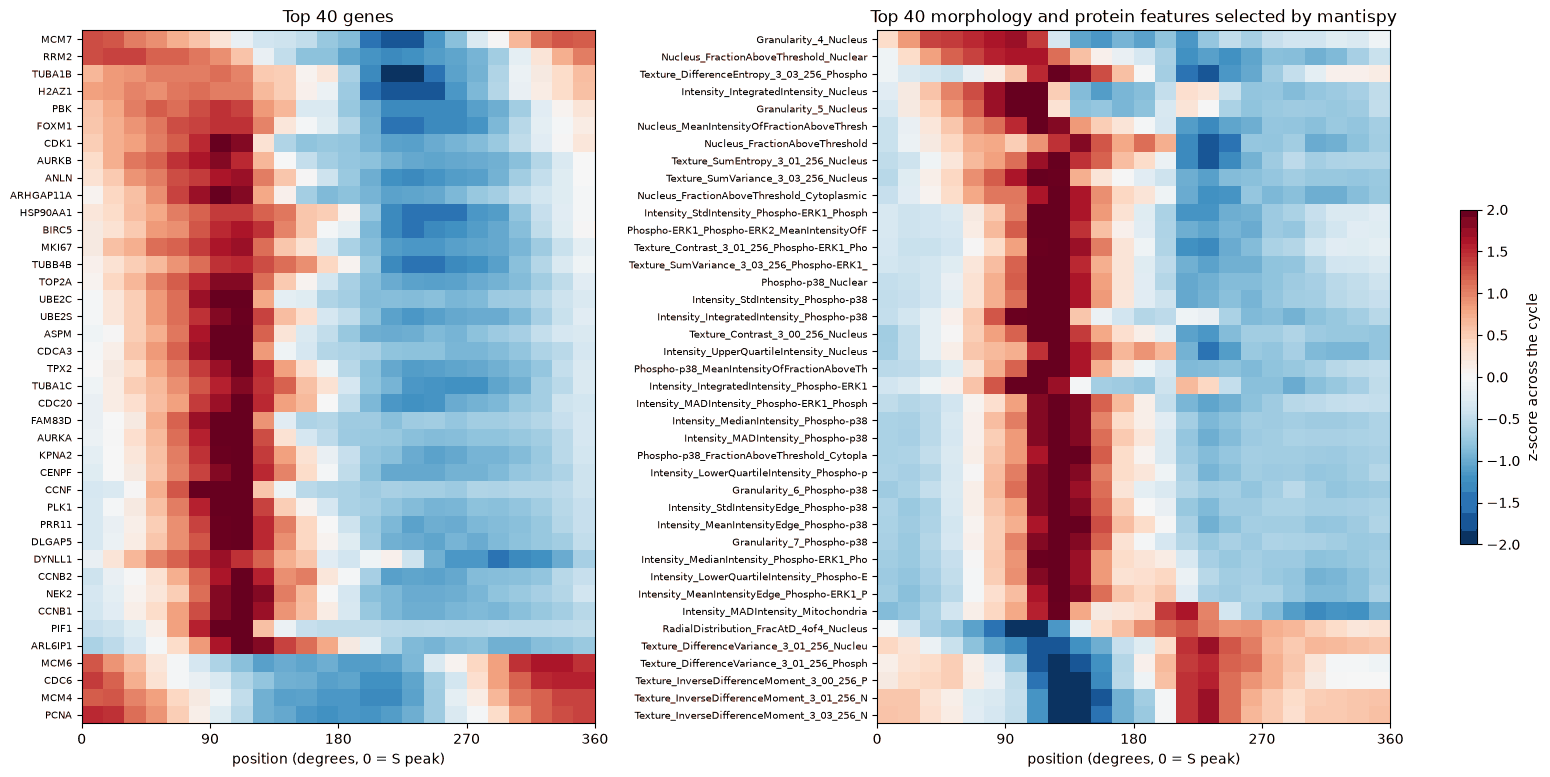

In [11]:
def heatmap(values, names, table, title, ax, n=40):
    top = table.head(n).sort_values("peak").index
    columns = pd.Index(names).get_indexer(top)
    bins_index = (np.degrees(shared["cycle_position"].values) // 15).astype(int)
    means = pd.DataFrame(centre(values[:, columns]), columns=top).groupby(bins_index).mean()
    scaled = (means - means.mean()) / means.std()
    image = ax.imshow(scaled.T, aspect="auto", cmap="RdBu_r", vmin=-2, vmax=2, extent=[0, 360, len(top), 0], interpolation="nearest")
    ax.set_yticks(np.arange(len(top)) + 0.5, [t[:42] for t in top], fontsize=7)
    ax.set_xticks(range(0, 361, 90))
    ax.set(xlabel="position (degrees, 0 = S peak)", title=title)
    return image


selected_table = feature_table[feature_table.index.isin(img.var_names[selected])]
fig, axes = plt.subplots(1, 2, figsize=(18, 9), gridspec_kw={"wspace": 0.55})
heatmap(gene_values, gene_names, gene_table, "Top 40 genes", axes[0])
image = heatmap(feature_values, feature_names, selected_table, "Top 40 morphology and protein features selected by mantispy", axes[1])
fig.colorbar(image, ax=axes, fraction=0.012, label="z-score across the cycle")
fig.savefig("figures/feature_heatmaps.png", dpi=130, bbox_inches="tight")
plt.show()

### What the genes and features say about the cycle

The genes form the known programme in order. Replication genes come first (PCNA 358, RRM2 47, TYMS 41 degrees), followed by histone variant and tubulin genes (H2AZ1 and TUBA1B 62 degrees). FOXM1, the main transcription factor of the G2/M programme, peaks at 79 degrees with CDK1, ahead of its targets TOP2A, PLK1 and CCNB1 at 94 to 109 degrees. Most of the strongest genes that aren't on the marker list are known cycle genes (KPNA2, UBE2S, ARL6IP1, PLK1), and their presence supports the ranking.

The arc after division is less studied and more interesting. MDM2 (151 degrees), PURPL (204 degrees) and CDKN1A, which encodes p21 (206 degrees), are p53 targets and A549 cells have wild-type p53, so a p53 response appears to follow division. CCND1 peaks close by (195 degrees), which is where cells commit to the next cycle, and p21 levels in early G1 are known to affect that decision. Effects in this arc are small (r2 below 0.03) and could partly be a composition effect, because G2/M genes take up less of each cell's counts here. Well-expressed genes such as ALDH1A1, PSAP and MT-CO2 are especially open to that reading.

In the images, the signal is mostly nuclear and in the two phospho stains. The nucleus features are the expected result of DNA doubling. Actin and membrane features change little (median r2 below 0.015), so cell shape carries little direct information about the phase. Accounting for cell size increases the signal of nuclear and phospho-p38 features, which shows that these signals don't come from larger cells being brighter.

## A small morphology panel that predicts the clock

Morphology features are highly correlated, so a ranking of all features mostly repeats one signal. We first reduce them with `mt.pp.feature_select` at stricter correlation cutoffs, leaving out background, IgG and `*_NuclearRatio` features. We then pick the features most tied to the clock and predict the position on wells the model hasn't seen. The panel is chosen on training wells only in each fold, so the accuracy isn't inflated. A random guess has a median error of 90 degrees.

In [12]:
not_biology = img.var_names[np.isin(modality, ["background", "control"]) | img.var_names.str.endswith("_NuclearRatio")]
fs = ad.AnnData(X=x[index].astype(np.float32), obs=img.obs.iloc[index].copy(), var=img.var.copy(), uns={"mantispy": dict(img.uns["mantispy"])})


def reduce(cutoff):
    mt.pp.feature_select(fs, operations=("correlation_threshold", "blocklist"), corr_threshold=cutoff, blocklist=list(not_biology), key_added=f"keep_{cutoff}")
    return fs.var[f"keep_{cutoff}"].values


reduced = {cutoff: cached(f"reduced_{cutoff}", lambda c=cutoff: reduce(c)) for cutoff in [0.9, 0.7, 0.5, 0.3]}
summary = pd.DataFrame({c: {"features": int(m.sum()), "nucleus": int((m & (channel == "Nucleus")).sum()), "protein": int((m & (modality == "protein")).sum()), "other cell paint": int((m & np.isin(channel, ["Actin", "Cell-Membrane", "Mitochondria"])).sum()), "shape": int((m & (modality == "shape")).sum())} for c, m in reduced.items()}).T
summary.index.name = "correlation cutoff"
summary

,features,nucleus,protein,other cell paint,shape
correlation cutoff,,,,,
0.9,360,52,158,141,9
0.7,176,25,68,75,8
0.5,108,15,37,50,6
0.3,46,6,11,25,4


In [13]:
target_xy = np.column_stack([np.sin(position), np.cos(position)])
fold_ids = np.zeros(len(position), dtype=int)
for fold, (_, test) in enumerate(GroupKFold(6).split(x, groups=wells)):
    fold_ids[test] = fold


def well_centred(values, labels):
    frame = pd.DataFrame(values)
    return (frame - frame.groupby(labels).transform("mean")).to_numpy(np.float32)


def strength(values, labels, xy):
    y, d = well_centred(values, labels), xy - xy.mean(0)
    beta = np.linalg.lstsq(d, y, rcond=None)[0]
    return ((d @ beta) ** 2).sum(0) / np.maximum((y**2).sum(0), 1e-9)


def panel_score(mask, sizes):
    columns = np.flatnonzero(mask)
    rows, picks = {}, {}
    for k in sizes:
        k = min(k, len(columns))
        guess = np.zeros_like(target_xy)
        for fold in np.unique(fold_ids):
            train, test = fold_ids != fold, fold_ids == fold
            rank = np.argsort(-strength(x[train][:, columns], wells[train], target_xy[train]))[:k]
            chosen = columns[rank]
            picks.setdefault(k, []).append(set(chosen))
            guess[test] = make_pipeline(StandardScaler(), Ridge(10)).fit(x[train][:, chosen], target_xy[train]).predict(x[test][:, chosen])
        angle = np.arctan2(guess[:, 0], guess[:, 1]) % (2 * np.pi)
        error = np.abs((angle - position + np.pi) % (2 * np.pi) - np.pi)
        rows[k] = {"circular correlation": circular_corr(angle, position), "median error (degrees)": np.degrees(np.median(error)), "features chosen in all folds": len(set.intersection(*picks[k]))}
    return pd.DataFrame(rows).T


SIZES = [1, 2, 5, 10, 20, 50, 100, 1000]
no_nucleus = ~np.isin(channel, ["Nucleus"]) & ~img.var_names.str.contains("Nuclear")
scores_by_set = cached("panels", lambda: {
    "cutoff 0.9": panel_score(reduced[0.9], SIZES),
    "cutoff 0.5": panel_score(reduced[0.5], SIZES),
    "cutoff 0.3": panel_score(reduced[0.3], SIZES),
    "cutoff 0.5, no nucleus features": panel_score(reduced[0.5] & no_nucleus, SIZES),
})
panels = pd.concat(scores_by_set, names=["feature set", "panel size"]).round(3)
panels

circular correlation  \
feature set                     panel size                         
cutoff 0.9                      1                          0.365   
                                2                          0.439   
                                5                          0.458   
                                10                         0.467   
                                20                         0.509   
                                50                         0.542   
                                100                        0.588   
                                360                        0.627   
cutoff 0.5                      1                          0.365   
                                2                          0.375   
                                5                          0.404   
                                10                         0.409   
                                20                         0.425   
                                50                         0.463   
                                100                        0.501   
                                108                        0.502   
cutoff 0.3                      1                          0.365   
                                2                          0.375   
                                5                          0.393   
                                10                         0.392   
                                20                         0.404   
                                46                         0.416   
cutoff 0.5, no nucleus features 1                          0.170   
                                2                          0.188   
                                5                          0.221   
                                10                         0.259   
                                20                         0.284   
                                50                         0.316   
                                90                         0.330   

                                            median error (degrees)  \
feature set                     panel size                           
cutoff 0.9                      1                           52.316   
                                2                           46.854   
                                5                           46.002   
                                10                          44.794   
                                20                          42.223   
                                50                          39.163   
                                100                         36.379   
                                360                         33.706   
cutoff 0.5                      1                           52.316   
                                2                           49.656   
                                5                           46.708   
                                10                          45.679   
                                20                          44.734   
                                50                          42.265   
                                100                         40.497   
                                108                         40.428   
cutoff 0.3                      1                           52.316   
                                2                           49.656   
                                5                           46.972   
                                10                          46.344   
                                20                          45.702   
                                46                          45.137   
cutoff 0.5, no nucleus features 1                           57.231   
                                2                           55.886   
                                5                           53.385   
                                10           

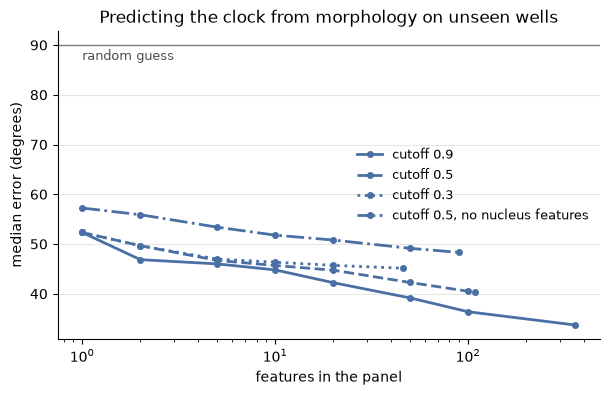

,r2,r2_given_size,peak,channel,modality,weight towards S peak (cos),weight 90 degrees later (sin)
Nucleus_FractionAboveThreshold_Nuclear,0.1115,0.1130,95.2717,Nucleus,cell_paint,0.0069,0.1894
Granularity_5_Nucleus,0.0401,0.0387,105.4264,Nucleus,cell_paint,-0.0348,0.1002
Granularity_2_Phospho-p38,0.0303,0.0278,301.0832,Phospho-p38,protein,0.0237,-0.0702
Granularity_4_Nucleus,0.0344,0.0417,75.3505,Nucleus,cell_paint,0.0063,0.1037
Granularity_2_Phospho-ERK1_Phospho-ERK2,0.0309,0.0279,313.7023,Phospho-ERK1_Phospho-ERK2,protein,0.0593,-0.0225
Granularity_8_Phospho-p38,0.0333,0.0331,129.1261,Phospho-p38,protein,-0.0295,0.0486
RadialDistribution_MeanFrac_4of4_Actin,0.0268,0.0243,352.3354,Actin,cell_paint,0.0457,-0.0079
Texture_DifferenceVariance_3_00_256_Phospho-p38,0.0235,0.0258,326.4073,Phospho-p38,protein,0.0584,-0.0283
Granularity_7_Phospho-ERK1_Phospho-ERK2,0.0253,0.0272,130.9699,Phospho-ERK1_Phospho-ERK2,protein,-0.0131,0.0063
Granularity_6_Phospho-ERK1_Phospho-ERK2,0.0273,0.0327,119.7310,Phospho-ERK1_Phospho-ERK2,protein,-0.0101,0.0151


In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
styles = {"cutoff 0.9": "-", "cutoff 0.5": "--", "cutoff 0.3": ":", "cutoff 0.5, no nucleus features": "-."}
for name, table_k in scores_by_set.items():
    ax.plot(table_k.index, table_k["median error (degrees)"], styles[name], color="#4a6fa5", lw=2, marker="o", ms=4, label=name)
ax.axhline(90, color="0.5", lw=1)
ax.text(1, 87, "random guess", color="0.3", fontsize=9)
ax.set(xscale="log", xlabel="features in the panel", ylabel="median error (degrees)", title="Predicting the clock from morphology on unseen wells")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="0.9", lw=0.8)
ax.legend(frameon=False, fontsize=9)
fig.savefig("figures/clock_panel.png", dpi=130, bbox_inches="tight")
plt.show()

PANEL_SIZE = 20
columns = np.flatnonzero(reduced[0.5])
rank = columns[np.argsort(-strength(x[:, columns], wells, target_xy))[:PANEL_SIZE]]
fit = make_pipeline(StandardScaler(), Ridge(10)).fit(x[:, rank], target_xy)
panel = feature_table.reindex(img.var_names[rank])[["r2", "r2_given_size", "peak", "channel", "modality"]].copy()
panel["weight towards S peak (cos)"], panel["weight 90 degrees later (sin)"] = fit[-1].coef_[1], fit[-1].coef_[0]
panel.to_csv("figures/clock_panel.csv")
all_kept = feature_table[feature_table.index.isin(img.var_names[reduced[0.5]])]
all_kept.to_csv("figures/cycle_morphology_decorrelated.csv")
panel.round(4)

### What the panel says about the biology

One nuclear feature, the share of the nucleus above an intensity threshold, gets within about 52 degrees, because it peaks at 95 degrees and mostly reports DNA content. It can separate G2 from G1 but can't tell the two directions around the circle apart, so a second independent signal is needed. The later picks fill that gap. Protein granularity in phospho-p38 and phospho-ERK and the radial distribution of actin peak at other positions (e.g., actin at 352 degrees and phospho-p38 granularity at 301 degrees), so they add information about G1 and S. Without any nucleus features the error stays at about 48 degrees, so signalling and cytoskeleton stains carry cycle information of their own, which is about three quarters of the way from chance (90 degrees) to the full model (34 degrees).

## A principled imaging clock

The panel above ranks features one by one, so it can pick several features that report the same signal. Here each feature has to earn its place, using the following steps.

First, we start from the features that remain after `mt.pp.feature_select`, which removes background, IgG and highly correlated features. Second, we add features one at a time within wells, each time taking the feature that explains the most remaining variance of the sine and cosine of the position. A clock needs both, because one signal alone can't tell the two directions around the circle apart. Third, we choose features on training wells only and score them on unseen wells. Fourth, we take the smallest panel within 5 degrees of the best panel, and report how often each feature is chosen across folds. Fifth, we check that the error is similar across knockouts and conditions, and compare with a nonlinear model to see what a linear model misses.

The target is the RNA position, which has its own error, so the scores measure agreement between imaging and RNA and set a lower bound on how well imaging tracks the cycle.

In [15]:
from sklearn.ensemble import HistGradientBoostingRegressor

PANEL_SIZES = [1, 2, 3, 5, 8, 10, 15, 20, 30, 50, 100]


def complementary_order(train, candidates, k=100):
    values = well_centred(x[train][:, candidates], wells[train]).copy()
    values /= np.maximum(values.std(0), 1e-6)
    residual = well_centred(target_xy[train], wells[train]).copy()
    picked = []
    for _ in range(min(k, len(candidates))):
        gain = ((values.T @ residual) ** 2).sum(1) / np.maximum((values**2).sum(0), 1e-3)
        gain[picked] = -1
        best = int(np.argmax(gain))
        picked.append(best)
        direction = values[:, best] / np.linalg.norm(values[:, best])
        residual -= np.outer(direction, direction @ residual)
        values -= np.outer(direction, direction @ values)
    return candidates[picked]


def circular_error(guess):
    angle = np.arctan2(guess[:, 0], guess[:, 1]) % (2 * np.pi)
    return angle, np.abs((angle - position + np.pi) % (2 * np.pi) - np.pi)


def complementary_panels(mask):
    candidates = np.flatnonzero(mask)
    guesses = {k: np.zeros_like(target_xy) for k in PANEL_SIZES}
    orders = []
    for fold in np.unique(fold_ids):
        train, test = fold_ids != fold, fold_ids == fold
        order = complementary_order(train, candidates)
        orders.append(order)
        for k in PANEL_SIZES:
            chosen = order[:k]
            guesses[k][test] = make_pipeline(StandardScaler(), Ridge(10)).fit(x[train][:, chosen], target_xy[train]).predict(x[test][:, chosen])
    return guesses, orders


is_morphology = np.isin(modality, ["cell_paint", "shape"])
is_nuclear = (channel == "Nucleus") | (modality == "shape")
panels = {
    "all features": cached("complementary_all", lambda: complementary_panels(reduced[0.9])),
    "no nucleus features": cached("complementary_no_nucleus", lambda: complementary_panels(reduced[0.9] & no_nucleus)),
    "morphology only": cached("complementary_morphology", lambda: complementary_panels(reduced[0.9] & is_morphology)),
    "morphology without nucleus": cached("complementary_morphology_no_nucleus", lambda: complementary_panels(reduced[0.9] & is_morphology & no_nucleus)),
    "nucleus and shape": cached("complementary_nuclear", lambda: complementary_panels(reduced[0.9] & is_nuclear)),
}
table = {}
for name, (guesses, orders) in panels.items():
    for k in PANEL_SIZES:
        angle, error = circular_error(guesses[k])
        table[(name, k)] = {"circular correlation": circular_corr(angle, position), "median error (degrees)": np.degrees(np.median(error)), "features chosen in all folds": len(set.intersection(*[set(o[:k]) for o in orders]))}
table = pd.DataFrame(table).T.round(3)
table.index.names = ["candidate features", "panel size"]
table

circular correlation  \
candidate features         panel size                         
all features               1                          0.365   
                           2                          0.439   
                           3                          0.447   
                           5                          0.474   
                           8                          0.511   
                           10                         0.519   
                           15                         0.534   
                           20                         0.549   
                           30                         0.580   
                           50                         0.599   
                           100                        0.616   
no nucleus features        1                          0.316   
                           2                          0.343   
                           3                          0.351   
                           5                          0.355   
                           8                          0.363   
                           10                         0.375   
                           15                         0.380   
                           20                         0.389   
                           30                         0.397   
                           50                         0.418   
                           100                        0.441   
morphology only            1                          0.365   
                           2                          0.396   
                           3                          0.409   
                           5                          0.416   
                           8                          0.437   
                           10                         0.445   
                           15                         0.470   
                           20                         0.484   
                           30                         0.496   
                           50                         0.503   
                           100                        0.513   
morphology without nucleus 1                          0.123   
                           2                          0.179   
                           3                          0.185   
                           5                          0.198   
                           8                          0.210   
                           10                         0.217   
                           15                         0.226   
                           20                         0.231   
                           30                         0.236   
                           50                         0.243   
                           100                        0.249   
nucleus and shape          1                          0.365   
                           2                          0.396   
                           3                          0.417   
                           5                          0.449   
                           8                          0.464   
                           10                         0.469   
                           15                         0.481   
                           20                         0.484   
                           30                         0.490   
                           50                         0.491   
                           100                        0.492   

                                       median error (degrees)  \
candidate features         panel size                           
all features               1                           52.316   
                           2                           46.854   
                           3                           46.661   
                           5                           44.032   
                           8                           41

In [16]:
errors_all = table.loc["all features", "median error (degrees)"]
clock_size = int(errors_all[errors_all <= errors_all.min() + 5].index.min())
guesses, orders = panels["all features"]
clock_angle, clock_error = circular_error(guesses[clock_size])
print("Chosen panel size:", clock_size)

final_order = complementary_order(np.ones(len(position), dtype=bool), np.flatnonzero(reduced[0.9]), clock_size)
counts = pd.Series(np.concatenate([o[:clock_size] for o in orders])).value_counts()
final_fit = make_pipeline(StandardScaler(), Ridge(10)).fit(x[:, final_order], target_xy)
clock_panel_final = img.var.iloc[final_order][["channel", "modality"]].astype(str).assign(
    folds_chosen=[int(counts.get(c, 0)) for c in final_order],
    weight_sin=final_fit[-1].coef_[0],
    weight_cos=final_fit[-1].coef_[1],
)
clock_panel_final["peak"] = feature_table["peak"].reindex(clock_panel_final.index).round(0)
clock_panel_final["r2_given_size"] = feature_table["r2_given_size"].reindex(clock_panel_final.index).round(3)
clock_panel_final.to_csv("figures/imaging_clock_panel.csv")
display(clock_panel_final.round(3))

groups = obs["target_gene"].astype(str).values
conditions_all = obs["condition"].astype(str).values
difference = (clock_angle - position + np.pi) % (2 * np.pi) - np.pi
rows = {}
for name, m in {"baseline": conditions_all == "baseline", "TNFa": conditions_all == "TNFa", **{g: groups == g for g in ["NTC", "CTNNB1", "TGFBR2", "GSK3B", "SMAD7", "IL1R1", "OR1I1"]}}.items():
    rows[name] = {"cells": int(m.sum()), "median error (degrees)": np.degrees(np.median(clock_error[m])), "circular correlation": circular_corr(clock_angle[m], position[m]), "imaging minus RNA (degrees)": np.degrees(np.angle(np.exp(1j * difference[m]).mean()))}
display(pd.DataFrame(rows).T.round(3))


def nonlinear_check():
    train, test = fold_ids != 0, fold_ids == 0
    columns = np.flatnonzero(reduced[0.9])
    guess = np.column_stack([HistGradientBoostingRegressor(random_state=0).fit(x[train][:, columns], target_xy[train, i]).predict(x[test][:, columns]) for i in range(2)])
    linear = make_pipeline(StandardScaler(), Ridge(10)).fit(x[train][:, columns], target_xy[train]).predict(x[test][:, columns])
    score = lambda g: np.degrees(np.median(np.abs((np.arctan2(g[:, 0], g[:, 1]) - position[test] + np.pi) % (2 * np.pi) - np.pi)))
    return {"linear, all features": score(linear), "gradient boosting, all features": score(guess)}


{k: round(float(v), 1) for k, v in cached("nonlinear_check", nonlinear_check).items()}

Chosen panel size: 20


,channel,modality,folds_chosen,weight_sin,weight_cos,peak,r2_given_size
Nucleus_FractionAboveThreshold_Nuclear,Nucleus,cell_paint,6,0.143,0.020,95.0,0.113
Intensity_IntegratedIntensity_Phospho-p38,Phospho-p38,protein,6,0.082,-0.031,118.0,0.124
Phospho-p38_FractionAboveThreshold_Cytoplasmic,Phospho-p38,protein,6,0.150,-0.099,127.0,0.121
Granularity_4_Nucleus,Nucleus,cell_paint,6,0.101,0.004,75.0,0.042
Granularity_5_Nucleus,Nucleus,cell_paint,6,0.108,-0.036,105.0,0.039
Texture_InverseDifferenceMoment_3_02_256_Cell-Membrane,Cell-Membrane,cell_paint,6,0.120,0.045,355.0,0.015
Phospho-p38_FractionAboveThreshold_Nuclear,Phospho-p38,protein,6,-0.067,0.045,108.0,0.021
Texture_SumVariance_3_03_256_Nucleus,Nucleus,cell_paint,6,0.094,-0.000,110.0,0.129
Texture_InfoMeas1_3_00_256_ERK1_ERK2,ERK1_ERK2,protein,6,-0.086,-0.027,270.0,0.016
Granularity_2_Phospho-ERK1_Phospho-ERK2,Phospho-ERK1_Phospho-ERK2,protein,6,-0.041,0.045,314.0,0.028


,cells,median error (degrees),circular correlation,imaging minus RNA (degrees)
baseline,104621.0,38.348,0.564,1.954
TNFa,101470.0,39.074,0.537,1.174
NTC,26943.0,37.882,0.547,-0.273
CTNNB1,45348.0,41.881,0.574,8.684
TGFBR2,7021.0,38.722,0.505,1.158
GSK3B,33952.0,37.120,0.538,-1.970
SMAD7,10175.0,38.183,0.542,0.036
IL1R1,13727.0,37.383,0.545,0.707
OR1I1,68925.0,38.211,0.543,0.293


{'linear, all features': 33.0, 'gradient boosting, all features': 29.6}

### What the imaging clock shows

A panel of 20 features reaches 39 degrees median error on unseen wells, against 35 degrees with 100 features and 90 degrees by chance. Using only morphology, without protein stains, the error is 41 degrees with 20 features and 39 degrees with 100. Gradient boosting improves on the linear model by about 3 degrees on one fold (30 and 33 degrees), so a linear clock misses little.

The panel works similarly across TNFa conditions and knockouts (37 to 42 degrees). CTNNB1 is the only exception to a zero offset: imaging places these cells about 9 degrees later than RNA does, while the RNA clock places them 17 degrees earlier than NTC cells. Imaging therefore sees about half of the CTNNB1 shift, which fits a real effect combined with an RNA-specific part. The panel was trained partly on CTNNB1 cells in other wells, so this estimate may understate the difference between the two clocks.

All of these numbers measure agreement with the RNA clock in A549 cells. We haven't tested the panel in another cell line or on another imaging system.


## UMAPs on only the features tied to the clock

If we keep only the 100 features most tied to the clock, cells should line up along the cycle. For RNA this is partly circular, because the clock was built from these genes, so 100 genes outside the top 500 with similar detection are shown as a comparison. For protein and morphology it's a fair test: we choose features on half of the wells and plot only cells from the other wells. The number in each title is the median distance in degrees between a cell's position and that of its 15 nearest neighbours in the feature space, where 90 means no alignment.

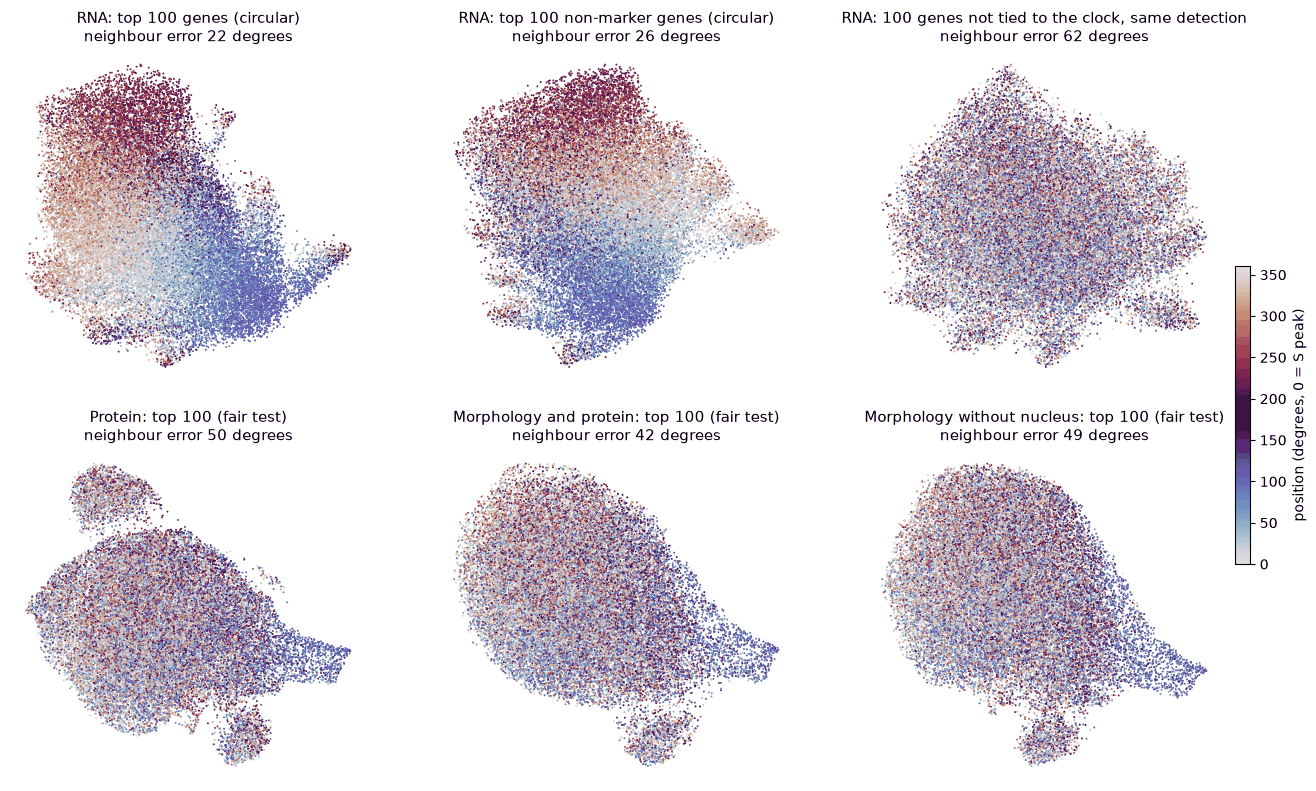

RNA: top 100 genes (circular)                           21.7
RNA: top 100 non-marker genes (circular)                25.6
RNA: 100 genes not tied to the clock, same detection    62.3
Protein: top 100 (fair test)                            49.9
Morphology and protein: top 100 (fair test)             41.7
Morphology without nucleus: top 100 (fair test)         48.5
Name: median neighbour error (degrees), dtype: float64

In [17]:
from sklearn.neighbors import NearestNeighbors

rng_umap = np.random.default_rng(0)
conditions = obs["condition"].astype(str).values
condition_wells = [np.unique(wells[conditions == c]) for c in np.unique(conditions)]
first_half = np.concatenate([rng_umap.permutation(w)[: len(w) // 2] for w in condition_wells])
is_train = np.isin(wells, first_half)
held_out = np.sort(rng_umap.choice(np.flatnonzero(~is_train), 30_000, replace=False))


def top_columns(mask, k=100):
    columns = np.flatnonzero(mask)
    return columns[np.argsort(-strength(x[is_train][:, columns], wells[is_train], target_xy[is_train]))[:k]]


def neighbour_error(values, angle):
    _, hits = NearestNeighbors(n_neighbors=16).fit(values).kneighbors(values)
    mean_angle = np.angle(np.exp(1j * angle[hits[:, 1:]]).mean(1))
    return float(np.degrees(np.median(np.abs((mean_angle - angle + np.pi) % (2 * np.pi) - np.pi))))


def embed(values):
    a = ad.AnnData(X=np.asarray(values, dtype=np.float32))
    sc.pp.pca(a, n_comps=min(30, a.n_vars - 1))
    sc.pp.neighbors(a, transformer="sklearn")
    sc.tl.umap(a, random_state=0)
    return a.obsm["X_pca"], a.obsm["X_umap"]


top_genes = gene_table.head(100).index
non_markers = gene_table[gene_table["marker"] == ""].head(100).index
pool = gene_table.iloc[500:]["detected"]
random_genes = []
for d in gene_table.loc[top_genes, "detected"].values:
    random_genes.append(pool.sub(d).abs().idxmin())
    pool = pool.drop(random_genes[-1])


def rna_values(genes):
    return np.clip(StandardScaler().fit_transform(rna[held_out, list(genes)].X.toarray()), -10, 10)


feature_sets = {
    "RNA: top 100 genes (circular)": lambda: rna_values(top_genes),
    "RNA: top 100 non-marker genes (circular)": lambda: rna_values(non_markers),
    "RNA: 100 genes not tied to the clock, same detection": lambda: rna_values(random_genes),
    "Protein: top 100 (fair test)": lambda: StandardScaler().fit_transform(x[held_out][:, top_columns(reduced[0.9] & (modality == "protein"))]),
    "Morphology and protein: top 100 (fair test)": lambda: StandardScaler().fit_transform(x[held_out][:, top_columns(reduced[0.9])]),
    "Morphology without nucleus: top 100 (fair test)": lambda: StandardScaler().fit_transform(x[held_out][:, top_columns(reduced[0.9] & no_nucleus)]),
}
angle_held = position[held_out]
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
errors = {}
for ax, (name, build) in zip(axes.ravel(), feature_sets.items()):
    pca_values, xy = cached(f"clock_umap_{name}", lambda b=build: embed(b()))
    errors[name] = neighbour_error(pca_values, angle_held)
    order = np.random.default_rng(1).permutation(len(xy))
    points = ax.scatter(xy[order, 0], xy[order, 1], c=np.degrees(angle_held[order]), cmap="twilight", vmin=0, vmax=360, s=2, linewidths=0, rasterized=True)
    ax.set_title(f"{name}\nneighbour error {errors[name]:.0f} degrees", fontsize=11)
    ax.set(xticks=[], yticks=[])
    ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
fig.colorbar(points, ax=axes, fraction=0.012, pad=0.01, label="position (degrees, 0 = S peak)")
plt.show()
pd.Series(errors, name="median neighbour error (degrees)").round(1)

### What the UMAPs show

Selecting features by the clock aligns cells along the cycle, as expected. In RNA, neighbouring cells differ by a median of 22 degrees with the top 100 genes and 26 degrees with the top 100 non-marker genes, against 62 degrees with 100 other genes of similar detection. The RNA result is partly circular, because the clock was built from these genes. The fair test is imaging on wells not used to choose features, where the error is 42 degrees with morphology and protein, 50 degrees with protein alone, and 48 degrees without nucleus features. Imaging features therefore place cells along the cycle without any RNA, less sharply than RNA does.

In [18]:
KNOCKOUTS = ["TGFBR2", "SMAD7", "IL1R1", "GSK3B", "CTNNB1", "OR1I1"]
target, condition = np.asarray(shared["Metadata_Perturbation"], dtype=str), np.asarray(shared["Metadata_Condition"], dtype=str)


def knn(values, y):
    return cross_val_score(KNeighborsClassifier(15), values, y, cv=5, scoring="balanced_accuracy").mean()


def compare_embeddings():
    knn_scores, activity, energy = {}, {}, {}
    for name, v in {k: views[k] for k in ["RNA PCA", "cycleVI z_other"]}.items():
        row = {"TNFa": knn(v, condition)}
        for ko in KNOCKOUTS:
            row[ko] = np.mean([knn(v[m], target[m]) for m in ((condition == c) & np.isin(target, [ko, "NTC"]) for c in ("baseline", "TNFa"))])
        knn_scores[name] = row
        a = view(v)
        a.obs_names = [str(i) for i in range(a.n_obs)]
        mt.io.stamp(a, resolution="object", feature_kind="embedding")
        mt.pp.annotate_controls(a, negcon=["NTC"])
        profiles = mt.tl.aggregate(a, by=("Metadata_Plate", "Metadata_Well", "Metadata_Guide"), func="mean")
        mt.tl.map(profiles, mode="activity", batch="Metadata_Condition", null_size=1000)
        activity[name] = profiles.uns["mantispy"]["map"].set_index("Metadata_Perturbation")["score"]
        within = a[a.obs["Metadata_Condition"] == "baseline"].copy()
        mt.tl.edistance(within, reference="negcon", n_permutations=200, max_reference=2000)
        energy[name] = within.uns["mantispy"]["edistance"].set_index("group")["distance"]
    return knn_scores, activity, energy


knn_scores, activity, energy = cached("embedding_comparison", compare_embeddings)
display(pd.DataFrame(knn_scores).T.round(3))
display(pd.DataFrame(activity).T.round(3))
pd.DataFrame(energy).T.round(4)

,TNFa,TGFBR2,SMAD7,IL1R1,GSK3B,CTNNB1,OR1I1
RNA PCA,0.837,0.537,0.504,0.503,0.512,0.626,0.5
cycleVI z_other,0.623,0.568,0.501,0.502,0.518,0.648,0.5


Metadata_Perturbation,CTNNB1,GSK3B,IL1R1,OR1I1,SMAD7,TGFBR2
RNA PCA,0.792,0.621,0.527,0.625,0.563,0.743
cycleVI z_other,0.977,0.638,0.581,0.593,0.615,0.931


group,CTNNB1,GSK3B,IL1R1,NTC,OR1I1,SMAD7,TGFBR2
RNA PCA,0.2951,0.0150,0.0080,-0.0014,-0.0026,0.0112,0.2176
cycleVI z_other,0.2002,0.0101,0.0039,0.0007,-0.0006,0.0080,0.1566


## Knockouts as readouts along the cycle

For each well, we compute the circular mean position and the share of cells in six sectors of the cycle for each knockout, and compare them with non-targeting cells in the same well. OR1I1 has no expected phenotype, so it shows the size of a difference expected by chance. Each guide is also tested on its own, because a real effect should appear in all four guides.

In [19]:
target_all, position_all = obs["target_gene"].astype(str).values, obs["cycle_position"].values
guide_all = obs["guide"].astype(str).values


def circular_shift(labels, ref_mask):
    rows = []
    for label in sorted(set(labels[~ref_mask]) - {"Undetermined"}):
        differences = []
        for well in np.unique(wells):
            a, b = position_all[(labels == label) & (wells == well)], position_all[ref_mask & (wells == well)]
            if len(a) >= 20:
                differences.append((stats.circmean(a) - stats.circmean(b) + np.pi) % (2 * np.pi) - np.pi)
        differences = np.degrees(differences)
        rows.append({"group": label, "wells": len(differences), "mean shift (degrees)": differences.mean(), "sd over wells": differences.std(ddof=1), "p": stats.ttest_1samp(differences, 0).pvalue})
    out = pd.DataFrame(rows).set_index("group")
    out = out.dropna(subset=["p"])
    out["q"] = stats.false_discovery_control(out["p"])
    return out


display(circular_shift(target_all, target_all == "NTC").round(4))
guide_shift = circular_shift(guide_all, target_all == "NTC")
guide_shift[guide_shift.index.str.startswith(("CTNNB1", "TGFBR2", "OR1I1"))].round(4)

,wells,mean shift (degrees),sd over wells,p,q
group,,,,,
CTNNB1,12,-17.3981,4.8015,0.0000,0.0000
GSK3B,12,1.9836,5.1224,0.2068,0.3738
IL1R1,12,-1.6526,3.0603,0.0882,0.2647
OR1I1,12,-0.9078,3.6965,0.4130,0.4957
SMAD7,12,-1.8541,5.2789,0.2492,0.3738
TGFBR2,12,-1.2837,7.4128,0.5607,0.5607


,wells,mean shift (degrees),sd over wells,p,q
group,,,,,
CTNNB1_1,12,-15.1714,5.4767,0.0000,0.0000
CTNNB1_2,12,-26.1842,8.7155,0.0000,0.0000
CTNNB1_3,12,-12.9263,15.2795,0.0137,0.0786
CTNNB1_4,12,-8.8665,7.6271,0.0020,0.0153
OR1I1_1,12,0.6595,6.7238,0.7404,0.9155
OR1I1_2,12,-0.7346,5.4866,0.6518,0.8819
OR1I1_3,12,-1.9704,3.9373,0.1109,0.3644
OR1I1_4,12,-1.1660,4.0127,0.3357,0.6435
TGFBR2_1,12,-0.5989,6.5198,0.7563,0.9155


In [20]:
sectors = pd.cut(position_all, np.linspace(0, 2 * np.pi, 7), include_lowest=True, labels=[f"{i * 60}-{(i + 1) * 60}" for i in range(6)]).astype(str)
fractions = pd.crosstab([wells, target_all], sectors, normalize="index")
rows = []
for ko in KNOCKOUTS:
    for sector in fractions.columns:
        a, b = fractions.xs(ko, level=1)[sector], fractions.xs("NTC", level=1)[sector]
        rows.append({"knockout": ko, "sector": sector, "difference": (a - b).mean(), "p": stats.ttest_rel(a, b).pvalue})
shift = pd.DataFrame(rows)
shift["q"] = stats.false_discovery_control(shift["p"])
display(shift.pivot(index="knockout", columns="sector", values="difference").round(4))
display(shift.sort_values("p").head(6).round(5))

well_condition = obs.groupby("Well", observed=True)["condition"].first().astype(str)
per_well = pd.crosstab(wells, sectors, normalize="index")
tnf = (per_well[well_condition.reindex(per_well.index).values == "TNFa"].mean() - per_well[well_condition.reindex(per_well.index).values == "baseline"].mean()).round(4)
print("TNFa minus baseline, share of cells per sector:", tnf.to_dict())

sector,0-60,120-180,180-240,240-300,300-360,60-120
knockout,,,,,,
CTNNB1,-0.0449,0.0161,0.0235,0.0452,-0.0113,-0.0287
GSK3B,0.0176,0.0006,-0.0047,-0.0032,-0.0067,-0.0037
IL1R1,0.0008,0.0023,0.0006,0.0037,0.0009,-0.0083
OR1I1,0.0025,0.0019,-0.0009,0.0042,-0.0017,-0.0059
SMAD7,0.0193,-0.0054,0.0007,0.0053,-0.0093,-0.0106
TGFBR2,-0.0065,0.0177,0.0040,0.0054,-0.0030,-0.0177


,knockout,sector,difference,p,q
27,CTNNB1,240-300,0.04522,0.00000,0.00000
24,CTNNB1,0-60,-0.04494,0.00000,0.00000
25,CTNNB1,120-180,0.01611,0.00000,0.00000
26,CTNNB1,180-240,0.02354,0.00001,0.00008
29,CTNNB1,60-120,-0.02865,0.00001,0.00009
1,TGFBR2,120-180,0.01770,0.00010,0.00058


TNFa minus baseline, share of cells per sector: {'0-60': 0.0064, '120-180': 0.0171, '180-240': 0.0167, '240-300': -0.0127, '300-360': -0.0151, '60-120': -0.0125}


A knockout with a strong RNA phenotype could move the RNA-based position without changing the cycle. So we repeat the test with measurements from imaging only: DNA content, cell area, and the position predicted from imaging by a model trained without any cells of that knockout.

In [21]:
rows = {}
for ko in ["CTNNB1", "TGFBR2", "OR1I1"]:
    train = target_all != ko
    fit = make_pipeline(StandardScaler(), Ridge(10)).fit(x[train][:, selected], np.column_stack([np.sin(position[train]), np.cos(position[train])]))
    guess = fit.predict(x[:, selected])
    guess = np.arctan2(guess[:, 0], guess[:, 1]) % (2 * np.pi)
    late = pd.Series((guess > np.radians(180)) & (guess < np.radians(240)))
    rna_late = pd.Series((position > np.radians(180)) & (position < np.radians(240)))
    frame_ko = pd.DataFrame({"well": wells, "target": target_all, "image": late.values, "rna": rna_late.values, "dna": obs["dna"].values, "area": np.log2(obs["cell_area"].values)})
    per_well = frame_ko[frame_ko["target"].isin([ko, "NTC"])].groupby(["well", "target"]).mean().unstack("target")
    row = {}
    for column, label in {"rna": "share in 180-240, RNA position", "image": "share in 180-240, imaging position", "dna": "DNA content (log2)", "area": "cell area (log2)"}.items():
        difference = per_well[column][ko] - per_well[column]["NTC"]
        row[f"{label}: difference"] = difference.mean()
        row[f"{label}: p"] = stats.ttest_1samp(difference, 0).pvalue
    rows[ko] = row
pd.DataFrame(rows).round(4)

,CTNNB1,TGFBR2,OR1I1
"share in 180-240, RNA position: difference",0.0235,0.0040,-0.0009
"share in 180-240, RNA position: p",0.0000,0.4021,0.5474
"share in 180-240, imaging position: difference",-0.0013,0.0114,-0.0001
"share in 180-240, imaging position: p",0.0591,0.0001,0.9403
DNA content (log2): difference,-0.0170,-0.0313,-0.0117
DNA content (log2): p,0.0195,0.0183,0.0381
cell area (log2): difference,0.2094,-0.1308,0.0040
cell area (log2): p,0.0000,0.0000,0.6019


## Two checks on the biological readings

The first table compares known target genes of each pathway between knockout and non-targeting cells within wells, using the knocked out gene itself as a check that the guides work. If CTNNB1 knockout slows the cycle through its known targets, CCND1 and MYC should fall. The second table shows each stain's mean intensity by position in units of standard deviation, within wells. If phospho-p38 and phospho-ERK rise around division because cells round up and look brighter, every stain should rise at the same position, including total ERK.

In [22]:
PATHWAY_GENES = {"CTNNB1": ["CTNNB1", "CCND1", "MYC", "AXIN2", "LEF1", "TCF7", "NKD1", "LGR5", "SP5"], "TGFBR2": ["TGFBR2", "SERPINE1", "SMAD7", "CTGF", "CCN2", "TGFBI", "SKIL"], "OR1I1": ["CCND1", "MYC", "SERPINE1"]}
rows = []
for knockout, genes in PATHWAY_GENES.items():
    genes = [g for g in genes if g in rna.var_names]
    m = np.isin(target_all, [knockout, "NTC"])
    frame = pd.DataFrame(rna[m, genes].X.toarray(), columns=genes).assign(well=wells[m], group=target_all[m])
    means = frame.groupby(["well", "group"]).mean()
    difference = means.xs(knockout, level="group") - means.xs("NTC", level="group")
    rows += [{"knockout": knockout, "gene": g, "difference (log expression)": difference[g].mean(), "NTC mean": means.xs("NTC", level="group")[g].mean(), "p": stats.ttest_1samp(difference[g], 0).pvalue} for g in genes]
display(pd.DataFrame(rows).round(4))
STAINS = ["Phospho-p38", "Phospho-ERK1_Phospho-ERK2", "ERK1_ERK2", "Phospho-HSP27", "Actin", "Mitochondria", "Cell-Membrane", "Nucleus"]
columns = {stain: img.var_names.get_loc(f"Intensity_MedianIntensity_{stain}") for stain in STAINS if f"Intensity_MedianIntensity_{stain}" in img.var_names}
stain_values = well_centred(x[:, list(columns.values())], wells) / x[:, list(columns.values())].std(0)
bins = pd.cut(np.degrees(position), np.arange(0, 361, 30), include_lowest=True, labels=[f"{i}-{i + 30}" for i in range(0, 360, 30)])
pd.DataFrame(stain_values, columns=list(columns)).groupby(bins, observed=True).mean().round(3)

,knockout,gene,difference (log expression),NTC mean,p
0,CTNNB1,CTNNB1,-0.2161,0.4574,0.0000
1,CTNNB1,CCND1,-0.0785,0.5870,0.0000
2,CTNNB1,MYC,0.0276,0.3690,0.0008
3,CTNNB1,AXIN2,-0.0007,0.0021,0.2347
4,CTNNB1,LEF1,0.0001,0.0002,0.6433
5,CTNNB1,TCF7,-0.0052,0.0354,0.0046
6,CTNNB1,NKD1,-0.0002,0.0016,0.6312
7,CTNNB1,LGR5,0.0000,0.0002,0.9536
8,CTNNB1,SP5,0.0002,0.0001,0.1725
9,TGFBR2,TGFBR2,-0.1175,0.3129,0.0000


,Phospho-p38,Phospho-ERK1_Phospho-ERK2,ERK1_ERK2,Phospho-HSP27,Actin,Mitochondria,Cell-Membrane,Nucleus
0-30,-0.199,-0.161,-0.086,-0.060,-0.084,-0.073,-0.080,-0.054
30-60,-0.126,-0.114,-0.050,-0.072,-0.082,-0.030,-0.082,-0.017
60-90,0.190,0.121,0.076,-0.045,-0.022,0.097,-0.029,0.066
90-120,0.589,0.448,0.163,0.001,0.019,0.177,0.101,0.116
120-150,0.965,0.721,0.406,0.092,0.181,0.288,0.320,0.337
150-180,0.327,0.248,0.257,0.110,0.183,0.088,0.243,0.224
180-210,0.007,0.091,0.273,0.219,0.285,0.226,0.215,0.147
210-240,-0.260,-0.102,0.065,0.175,0.205,0.217,0.071,-0.126
240-270,-0.239,-0.150,-0.046,0.074,0.110,-0.046,-0.009,-0.080
270-300,-0.216,-0.166,-0.108,0.024,0.018,-0.158,-0.023,-0.058


### What the checks show

The guides work and the pathways respond. CTNNB1 mRNA falls by 0.22 log expression, and TGFBR2 knockout lowers its known targets TGFBI (-0.36) and SERPINE1 (-0.17). CCND1 falls in CTNNB1 knockouts (-0.08), which fits a slower entry into S, but MYC rises slightly (+0.03) instead of falling. Classic Wnt targets (AXIN2, LEF1, NKD1, LGR5, SP5) are almost undetected in these cells, so they can't confirm or reject a Wnt effect. The CCND1 result also can't separate the two readings of the clock shift, because CCND1 peaks in G1 and could change either way.

The stain table partly answers the rounding question. At 120 to 150 degrees every stain gets brighter (0.18 to 0.41 standard deviations for actin, mitochondria, membrane, nucleus and total ERK), which points to a general effect such as cell rounding. Phospho-p38 (0.97) and phospho-ERK (0.72) rise about two to three times as much, and phospho-ERK rises more than total ERK (0.41). Part of the phospho signal is therefore specific to these stains, although we can't separate kinase activity from antibody cross-reactivity in mitotic cells. Phospho-HSP27, a p38 target, peaks later at 180 to 210 degrees (0.22), which could fit signalling downstream of p38 but is a small effect.

### Do the knockouts change the cycle?

CTNNB1 knockout moves cells on the RNA clock by -17 degrees, and all four guides shift in the same direction. In share of cells, 8.5 percentage points move from the 300 to 120 degree arc (G1/S to G2/M) to the 120 to 300 degree arc (G1). Larger cells (+0.21 log2 in area) would fit a slower or longer G1, since cells that stay longer in G1 keep growing, and beta-catenin promotes CCND1 expression. However, the imaging evidence doesn't support the shift. The imaging position shows no increase, and the DNA content difference (-0.017) is about the same as in OR1I1 controls (-0.012). The other reading is that CTNNB1 knockout changes expression of genes that the clock uses without changing the cycle. We can't choose between the two readings with these data. A direct measure such as EdU labelling would settle it.

TGFBR2 knockout has a strong effect on cells (`mt.tl.map` 0.74, energy distance 0.22, area -0.13 log2) with no shift on the RNA clock, although imaging shows a small increase in the 180 to 240 degree sector (1.1 percentage points). It shows that a strong phenotype doesn't have to move the clock, so the CTNNB1 shift isn't a general artifact of strong knockouts. GSK3B, SMAD7 and IL1R1 show no shift, and the library contains no direct cell cycle regulator to act as a positive control. TNFa moves about 3 percentage points of cells into the 120 to 240 degree arc, and this effect is small.

## Do knockout effects depend on the position in the cycle?

We compare energy distances from non-targeting cells in six sectors of the cycle with `mt.tl.edistance` on the cell painting features. If an effect depends on the position, its distance should change across sectors while OR1I1 stays near zero.

In [23]:
paint_mask = selected & np.isin(modality, ["cell_paint", "shape"])
paint_pcs = PCA(30, random_state=0).fit_transform(x[:, paint_mask])
rows = {}
for sector in sorted(set(sectors), key=lambda s: int(s.split("-")[0])):
    m = (sectors == sector) & (obs["condition"].astype(str).values == "baseline")
    a = ad.AnnData(X=paint_pcs[m].astype(np.float32), obs=pd.DataFrame({"Metadata_Plate": "Cytos-MPS_TNFa", "Metadata_Well": wells[m], "Metadata_Perturbation": target_all[m], "Metadata_ImageID": wells[m], "Metadata_ObjectType": "cell", "Metadata_ObjectNumber": np.arange(m.sum())}, index=img.obs_names[m]))
    mt.io.stamp(a, resolution="object", feature_kind="embedding")
    mt.pp.annotate_controls(a, negcon=["NTC"])
    mt.tl.edistance(a, reference="negcon", n_permutations=100, max_reference=1000)
    rows[sector] = a.uns["mantispy"]["edistance"].set_index("group")["distance"]
pd.DataFrame(rows).round(4)

,0-60,60-120,120-180,180-240,240-300,300-360
group,,,,,,
CTNNB1,0.2698,0.3106,0.3544,0.3799,0.3375,0.2612
GSK3B,0.0302,0.0170,0.0056,0.0056,0.0646,0.0561
IL1R1,0.0045,0.0188,0.0327,0.0156,0.0172,0.0033
NTC,0.0177,0.0107,0.1525,-0.0900,0.0249,0.0056
OR1I1,0.0039,0.0177,0.0164,0.0083,-0.0060,-0.0057
SMAD7,0.0034,0.0335,0.0567,0.0276,0.0498,0.0130
TGFBR2,0.5944,0.4847,0.5477,0.4355,0.8542,0.6651
